In [35]:
import torch
import torch.nn as nn
import numpy as np
import matplotlib.pyplot as plt
from torchdiffeq import odeint
from scipy.integrate import solve_ivp
import tqdm

# PARAMETERS AND DATA PREPARATION
alpha, beta, delta, gamma = 1.5, 1.0, 1.0, 3.0

def f(X):
    x1, x2 = X

    dx1_dt = alpha * x1 - beta * x1 * x2
    dx2_dt = delta * x1 * x2 - gamma * x2
    return torch.stack([dx1_dt, dx2_dt], dim=1)

X0 = [1.0, 1.0]
t_span = [0.0, 10.0]
t_eval = np.linspace(0.0, 10.0, 500)
#sol_real = solve_ivp(f, t_span, X0, t_eval=t_eval)
sol_real = solve_ivp(f_scipy := lambda t, s: [alpha*s[0] - beta*s[0]*s[1], delta*s[0]*s[1] - gamma*s[1]], t_span, X0, t_eval=t_eval)

time = torch.tensor(t_eval, dtype=torch.float32)
X_real = torch.tensor(sol_real.y, dtype=torch.float32).T

meanX = X_real.mean(dim=0, keepdim=True)
stdX = X_real.std(dim=0, keepdim=True)
X_norm = (X_real - meanX) / stdX
X0_norm = X_norm[0]

dXdt_real = f(X_real.T)

In [36]:
# MODEL DEFINITION
class NeuralField(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(2, 32),
            nn.Tanh(),
            nn.Linear(32, 32),
            nn.Tanh(),
            nn.Linear(32, 32),
            nn.Tanh(),
            nn.Linear(32, 2)
        )

    def forward(self, x):
        return self.net(x)

# TRAINING
model = NeuralField()
optimizer = torch.optim.Adam(model.parameters(), lr=3e-3)

epochs = 2000
model.train()
progress_bar = tqdm.tqdm(range(epochs), desc=f"Starting training...")
min_loss = 1e6
for epoch in progress_bar:
    dXdt_pred = model(X_norm)

    optimizer.zero_grad()
    loss = torch.mean((dXdt_pred - dXdt_real)**2)
    loss.backward()
    optimizer.step()

    current_loss = loss.item()

    if current_loss < min_loss:
        torch.save(model.state_dict(), "lk_vectorfield.pt")
        min_loss = current_loss

    if epoch % 50 == 0:
        progress_bar.set_postfix(loss=f"{current_loss:.6f}", min_loss=f"{min_loss:.6f}")

print("TRAINING SUCCESS!")

Starting training...: 100%|██████████| 2000/2000 [00:11<00:00, 181.47it/s, loss=0.000580, min_loss=0.000580]

TRAINING SUCCESS!


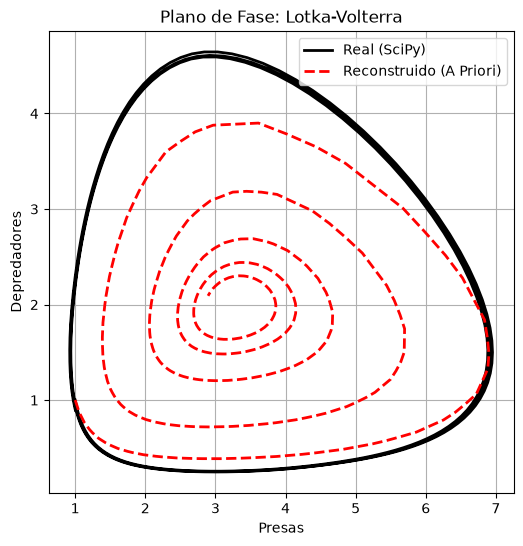

In [37]:
# --- EVALUACIÓN Y VALIDACIÓN FINAL CON ODEINT ---
model_eval = NeuralField()
model_eval.load_state_dict(torch.load("lk_vectorfield.pt"))
model_eval.eval()

class ODEWrapper(nn.Module):
    def __init__(self, net):
        super().__init__()
        self.net = net
    def forward(self, t, x):
        return self.net(x)

ode_func = ODEWrapper(model_eval)

with torch.no_grad():
    X_pred_norm = odeint(ode_func, X0_norm, time, method='rk4', options={'step_size': 0.05})
    X_pred_rescaled = (X_pred_norm * stdX + meanX).numpy()

# Gráfica rápida del atractor
plt.figure(figsize=(6, 6))
plt.plot(X_real.numpy()[:, 0], X_real.numpy()[:, 1], 'k-', label='Real (SciPy)', linewidth=2)
plt.plot(X_pred_rescaled[:, 0], X_pred_rescaled[:, 1], 'r--', label='Reconstruido (A Priori)', linewidth=2)
plt.title("Plano de Fase: Lotka-Volterra")
plt.xlabel("Presas")
plt.ylabel("Depredadores")
plt.legend()
plt.grid(True)
plt.show()